# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [2]:
df = pd.read_csv("dataset/Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    optimizer.zero_grad() #clear gradients from the previous epoch
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

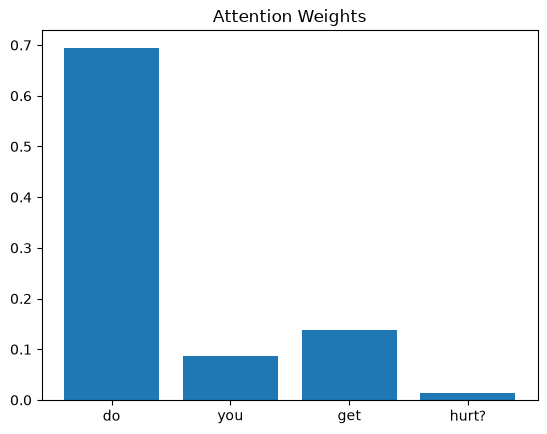

In [6]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

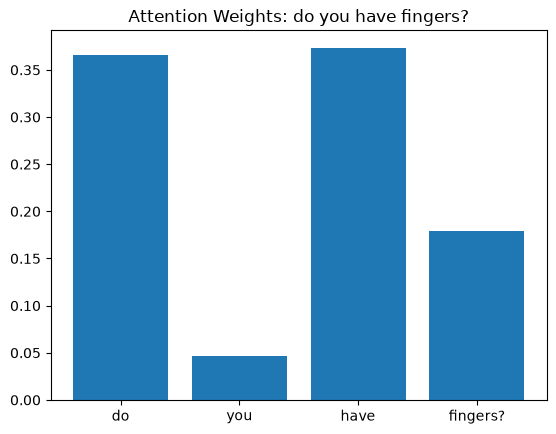

Highest attention word: have
Predicted answer: I don't have a body.
True answer:      I don't have a body.


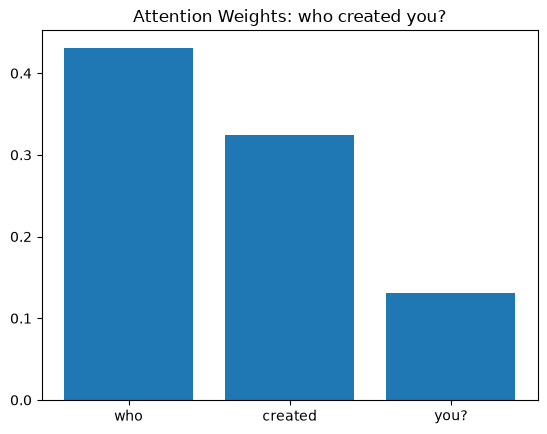

Highest attention word: who
Predicted answer: People created me.
True answer:      People created me.


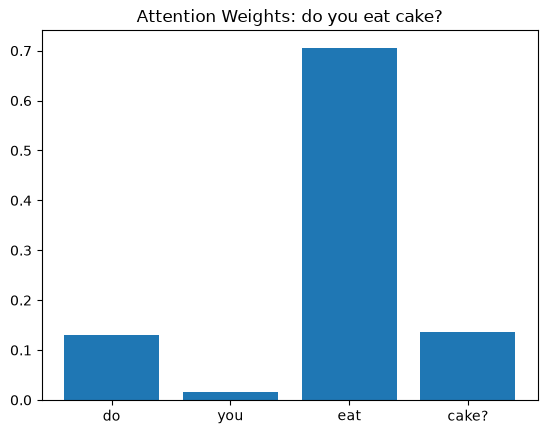

Highest attention word: eat
Predicted answer: I don't need to eat.
True answer:      I don't need to eat.


In [7]:
import numpy as np

answers = {}
for answer_id, answer in zip(df["answer_id"], df["answer"]):
    answers[answer_id] = answer

def show_attention(i):
    question = df["question"][i]
    words = question.split()

    with torch.no_grad():
        prediction, weights = model(X[i:i+1])

    w = weights[0, :len(words)].tolist()
    plt.bar(words, w)
    plt.title("Attention Weights: " + question)
    plt.show()

    print("Highest attention word:", words[w.index(max(w))])
    print("Predicted answer:", answers[np.argmax(prediction[0].numpy())])
    print("True answer:     ", df["answer"][i])

for i in [1, 48, 98]:
    show_attention(i)

**Answer:**

**Question 1, "do you have fingers?":** the highest attention word is **have** (0.37). "do" gets the same weight (0.37) and "fingers" gets about half as much (0.18). The model predicted the correct answer.

**Question 2, "who created you?":** the highest attention word is **who** (0.43), followed by "created" (0.32). The model predicted the correct answer.

**Question 3, "do you eat cake?":** the highest attention word is **eat** (0.71). The model predicted the correct answer.

Only partly. In "do you eat cake?" the model attends most to **eat**, which is the word that matters: every question in that group is about eating. In the other two questions the top word is not the word a person would choose. For "do you have fingers?" the important word is "fingers", but the model attends more to "do" and "have". For "who created you?" it attends most to "who" rather than "created".

These words still help on this dataset. Many questions in the "I don't have a body" group start with "do you ..." or "do you have ...", and many in the "People created me" group start with "who ...". So the model learned which words separate the answer groups in *this* data, not which words carry the meaning. High attention means "useful for the model's decision", which is not always the same as "important for a human".

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

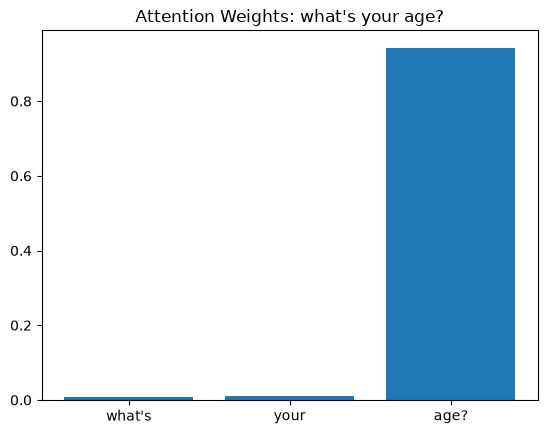

Highest attention word: age?
Predicted answer: Not at all.
True answer:      Age doesn't really apply to me.


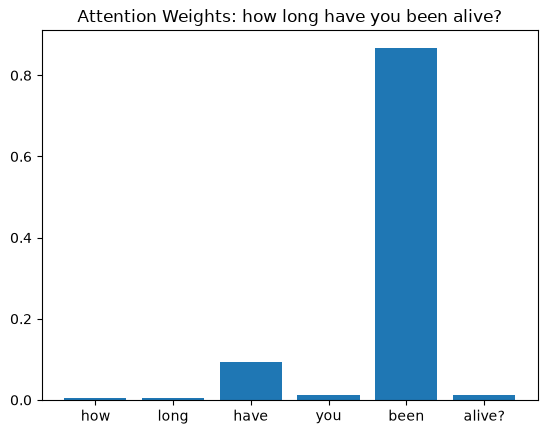

Highest attention word: been
Predicted answer: I'm better at answering questions.
True answer:      Age doesn't really apply to me.


In [8]:
for i in [20, 16]:
    show_attention(i)

**Answer:** Both questions ask about age and have the same answer ("Age doesn't really apply to me."), but the model focuses on different words.

For "what's your age?" almost all the attention (about 0.94) is on **age**. For "how long have you been alive?" most of the attention (about 0.87) is on **been**, a little is on "have", and almost none is on "alive".

So the model focuses on **different** words, and in this run it predicted the wrong answer for both questions ("Not at all." and "I'm better at answering questions."), even though both questions were in the training data.

This shows that attention works on the actual words in the sentence, not on their meaning. Each word gets a weight based on its learned vector and the RNN state, so two sentences with the same meaning but no shared words get unrelated attention patterns. Attention also only shows *where* the model looks, not whether it understood: it looked at "age", which is correct, and still chose the wrong answer, because the model is small and was trained for only 50 epochs on 168 questions. To make similar questions behave alike, the model would need more training data, or word vectors that already know "age" and "alive" are related (for example Word2Vec from Labs 5 and 6).